# **Viewing classes in Directory**





In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import math 

In [2]:
dir_example = "Data/Train"

train_classes = os.listdir(dir_example)
print(train_classes)
print("Class length:", len(train_classes))

['cardboard', 'electronics', 'glass', 'metal', 'organicwaste', 'plastic']
Class length: 6


# **Visualizing Images in Dataset from each class**

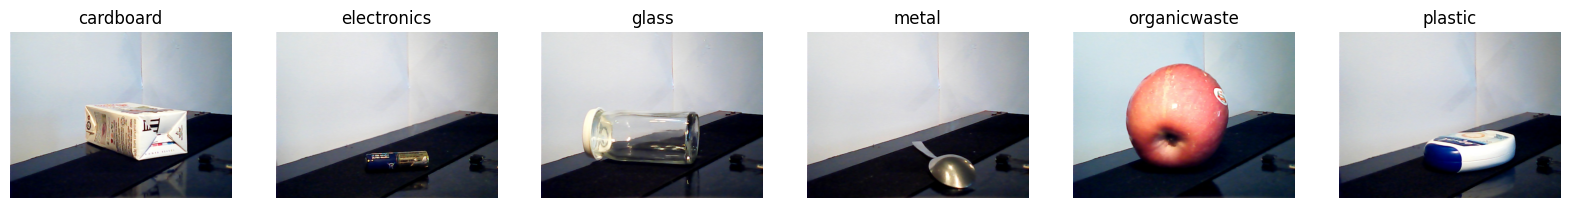

In [3]:
dir_example = "Data/Train"

# Get a list of class folders
class_folders = [folder for folder in os.listdir(dir_example) if os.path.isdir(os.path.join(dir_example, folder))]

# Generate the subplots
num_classes = len(class_folders)
fig, axs = plt.subplots(1, num_classes, figsize=(20, 15))

# Plot one image from each class
for i, class_folder in enumerate(class_folders):
    class_path = os.path.join(dir_example, class_folder)
    images = [image for image in os.listdir(class_path) if image.endswith('.jpg') or image.endswith('.png')]
    if len(images) > 0:
        image_path = os.path.join(class_path, images[0])
        image = Image.open(image_path)
        axs[i].imshow(image)
        axs[i].axis('off')
        axs[i].set_title(class_folder)

# Show the plot
plt.show()

# **Importing required Libraries for Model**

In [4]:
from tensorflow.keras.models import Sequential
from keras.layers import Conv2D, Flatten, MaxPooling2D, Dense, Dropout, SpatialDropout2D
from tensorflow.keras.losses import sparse_categorical_crossentropy, binary_crossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# **Data Configuration**

In [5]:
train = 'Data/Train'
test = 'Data/Test'

# **Data Preparation and Loading**

### *Creating a Generator for Training Set*

In [6]:

train_generator = ImageDataGenerator(rescale = 1/255)

train_generator = train_generator.flow_from_directory(train,
                                                      target_size = (300,300),
                                                      batch_size = 3,
                                                      class_mode = 'sparse')

labels = (train_generator.class_indices)
print(labels,'\n')

labels = dict((v,k) for k,v in labels.items())
print(labels)

Found 192 images belonging to 6 classes.
{'cardboard': 0, 'electronics': 1, 'glass': 2, 'metal': 3, 'organicwaste': 4, 'plastic': 5} 

{0: 'cardboard', 1: 'electronics', 2: 'glass', 3: 'metal', 4: 'organicwaste', 5: 'plastic'}


### *Creating a Generator for Testing Set*

In [7]:
test_generator = ImageDataGenerator(rescale = 1./255)

test_generator = test_generator.flow_from_directory(test,
                                                    target_size = (300,300),
                                                    batch_size = 5,
                                                    class_mode = 'sparse')

test_labels = (test_generator.class_indices)
print(test_labels,'\n')

test_labels = dict((v,k) for k,v in test_labels.items())
print(test_labels)

Found 45 images belonging to 6 classes.
{'cardboard': 0, 'electronics': 1, 'glass': 2, 'metal': 3, 'organicwaste': 4, 'plastic': 5} 

{0: 'cardboard', 1: 'electronics', 2: 'glass', 3: 'metal', 4: 'organicwaste', 5: 'plastic'}


In [8]:
for image_batch, label_batch in train_generator:
  break
image_batch.shape, label_batch.shape


((3, 300, 300, 3), (3,))

In [9]:
for image_batch, label_batch in test_generator:
  break
image_batch.shape, label_batch.shape

((5, 300, 300, 3), (5,))

# **Writing the labels into a text file '*Labels.txt* '**

In [10]:
print(train_generator.class_indices)
Labels = '\n'.join(sorted(train_generator.class_indices.keys()))

with open('Labels.txt', 'w') as file:
  file.write(Labels)

{'cardboard': 0, 'electronics': 1, 'glass': 2, 'metal': 3, 'organicwaste': 4, 'plastic': 5}


# **Model Architecture**

In [11]:
model=Sequential()

#Convolution blocks
model.add(Conv2D(32, kernel_size = (3,3), padding='same',input_shape=(300,300,3),activation='relu'))
model.add(MaxPooling2D(pool_size=2)) 

model.add(Conv2D(64, kernel_size = (3,3), padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=2)) 

model.add(Conv2D(32, kernel_size = (3,3), padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=2)) 

#Classification layers
model.add(Flatten())

model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(32,activation='relu'))

model.add(Dropout(0.2))
model.add(Dense(6,activation='softmax'))


model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 300, 300, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 150, 150, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 150, 150, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 75, 75, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 75, 75, 32)        18464     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 37, 37, 32)        0

# **Model Compilation**

In [12]:
model.compile(optimizer = 'Adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

# **Training the Model (batch_size = 10, epochs = 25)**

In [13]:
model.fit(train_generator,
          epochs=25,
          steps_per_epoch=50//3)

Epoch 1/25
16/16 [==============================] - 8s 299ms/step - loss: 1.9038 - accuracy: 0.1250
Epoch 2/25
16/16 [==============================] - 5s 309ms/step - loss: 1.8199 - accuracy: 0.2292
Epoch 3/25
16/16 [==============================] - 5s 312ms/step - loss: 1.7880 - accuracy: 0.1667
Epoch 4/25
16/16 [==============================] - 5s 311ms/step - loss: 1.8424 - accuracy: 0.2500
Epoch 5/25
16/16 [==============================] - 5s 309ms/step - loss: 1.7884 - accuracy: 0.2292
Epoch 6/25
16/16 [==============================] - 5s 312ms/step - loss: 1.6500 - accuracy: 0.3333
Epoch 7/25
16/16 [==============================] - 5s 302ms/step - loss: 1.6009 - accuracy: 0.2292
Epoch 8/25
16/16 [==============================] - 5s 299ms/step - loss: 1.4601 - accuracy: 0.4583
Epoch 9/25
16/16 [==============================] - 5s 305ms/step - loss: 1.3964 - accuracy: 0.3958
Epoch 10/25
16/16 [==============================] - 5s 305ms/step - loss: 1.1628 - accuracy: 0.5208

# Evaluate the model on the test dataset

In [14]:
# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(test_generator)

# Print the accuracy score
print('Test Accuracy:', test_accuracy)

9/9 [==============================] - 1s 106ms/step - loss: 0.0768 - accuracy: 1.0000
Test Accuracy: 1.0


# **Testing Predictions**

In [30]:
# from keras.preprocessing import image
import keras.utils as ku
import numpy as np
test_img = 'Data\Test\image7.jpg' # change here your image name
img = ku.load_img(test_img, target_size = (300,300))
img = ku.img_to_array(img, dtype=np.uint8)
img = np.array(img)/255.0
prediction = model.predict(img[np.newaxis, ...])

#print("Predicted shape",p.shape)
print("Probability:",np.max(prediction[0], axis=-1))
predicted_class = labels[np.argmax(prediction[0], axis=-1)]
print("Classified:",predicted_class,'\n')

plt.axis('off')
plt.imshow(img.squeeze())
plt.title("Loaded Image")

FileNotFoundError: [Errno 2] No such file or directory: 'Data\\Test\\image7.jpg'

In [31]:
classes = []
probability = []

for i,j in enumerate(prediction[0],0):
  print(labels[i].upper(),':',round(j*100,2),'%')

CARDBOARD : 1.31 %
ELECTRONICS : 86.68 %
GLASS : 3.84 %
METAL : 3.58 %
ORGANICWASTE : 0.52 %
PLASTIC : 4.07 %


1/1 [==============================] - 0s 97ms/step
Probability: 0.8312678
Classified: electronics 



Text(0.5, 1.0, 'Loaded Image')

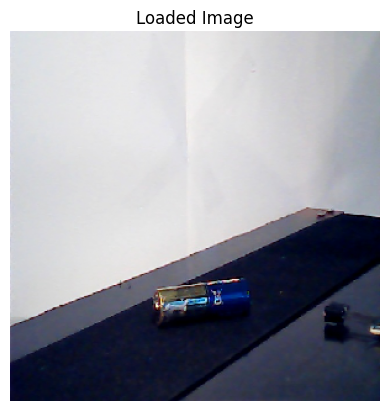

In [32]:
test_img = 'Data/Test/image2.jpg'
img = ku.load_img(test_img, target_size = (300,300))
img = ku.img_to_array(img, dtype=np.uint8)
img = np.array(img)/255.0
prediction = model.predict(img[np.newaxis, ...])

#print("Predicted shape",p.shape)
print("Probability:",np.max(prediction[0], axis=-1))
predicted_class = labels[np.argmax(prediction[0], axis=-1)]
print("Classified:",predicted_class,'\n')

plt.axis('off')
plt.imshow(img.squeeze())
plt.title("Loaded Image")

In [33]:
classes = []
probability = []

for i,j in enumerate(prediction[0],0):
  print(labels[i].upper(),':',round(j*100,2),'%')

CARDBOARD : 3.77 %
ELECTRONICS : 83.13 %
GLASS : 3.24 %
METAL : 8.85 %
ORGANICWASTE : 0.11 %
PLASTIC : 0.9 %


1/1 [==============================] - 0s 93ms/step
Probability: 0.9882074
Classified: cardboard 



Text(0.5, 1.0, 'Loaded Image')

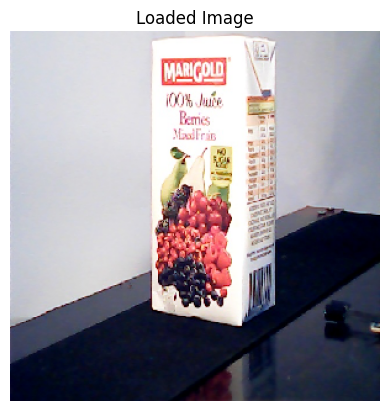

In [34]:
test_img = 'Data/Test/image4.jpg'
img = ku.load_img(test_img, target_size = (300,300))
img = ku.img_to_array(img, dtype=np.uint8)
img = np.array(img)/255.0
prediction = model.predict(img[np.newaxis, ...])

#print("Predicted shape",p.shape)
print("Probability:",np.max(prediction[0], axis=-1))
predicted_class = labels[np.argmax(prediction[0], axis=-1)]
print("Classified:",predicted_class,'\n')

plt.axis('off')
plt.imshow(img.squeeze())
plt.title("Loaded Image")

In [35]:
classes = []
probability = []

for i,j in enumerate(prediction[0],0):
  print(labels[i].upper(),':',round(j*100,2),'%')

CARDBOARD : 98.82 %
ELECTRONICS : 0.76 %
GLASS : 0.4 %
METAL : 0.0 %
ORGANICWASTE : 0.0 %
PLASTIC : 0.01 %


### *Testing shows that the model is fairly successful in classifying the type of waste*

## ***Saving model as 'model.h5'***

In [36]:
model.save('weights/model.h5')
print("model file genrated successfull")

model file genrated successfull


C:\Users\65911\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


# Now test on mode load and test

In [37]:
print("Probability:",np.max(prediction[0], axis=-1))

Probability: 0.9882074
